# Model — Prediksi Lonjakan RSV Admissions (Spark ML / PySpark)
**File:** `model_2_09020624025.ipynb`

Notebook ini mengeksekusi tahapan pemodelan **Spark ML** sesuai diagram arsitektur & flowchart jalur **RSV Admissions**:
- **Input:** `../data/processed/features_hospital_timeseries.parquet` hasil ETL `eda_2_09020624025.ipynb`
- **Urutan Flowchart:**
  1. `String Encode` (`StringIndexer` pada `state` → `state_idx`)
  2. `Vector Assembling` (`lag_1, lag_2, rolling_mean_4w, bed_occ_ratio_lag1, week_of_year, state_idx` → `features`)
  3. `Split Data` → `70% Train`, `20% Validate`, `10% Test`
  4. `max_dept, num_tree Tuning Train` → `Random Forest Execution` → `Confusion Matrices, Accuracy, F1 Score` → Diamond `70% < X < 80%` (loop tuning otomatis maks. 3 putaran)
  5. `Contribute Rank / Importance Feature`
  6. `Load With Accuracy, Hyperparam, Treshold result` → `Stored` ke Local Storage (`../models/`)

## 0. Instalasi Library

In [1]:
!pip install -q pyspark==3.5.1 matplotlib pyarrow


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Import Library & Konfigurasi I/O Windows Tanpa Instalasi Hadoop

In [2]:
import os
import json
import shutil
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StringIndexer
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

warnings.filterwarnings("ignore", category=FutureWarning)


def setup_windows_spark_io():
    """Siapkan shim minimal (~200 KB) hanya jika berjalan di Windows tanpa HADOOP_HOME,
    dengan forward-slash (/) agar tidak terpotong oleh parser JVM extraJavaOptions."""
    if os.name != "nt":
        return
    existing = os.environ.get("HADOOP_HOME")
    if existing:
        clean_existing = existing.replace("\\", "/")
        os.environ["HADOOP_HOME"] = clean_existing
        os.environ["hadoop.home.dir"] = clean_existing
        return
    shim_home = os.path.abspath("../.spark_win_io").replace("\\", "/")
    bin_dir = f"{shim_home}/bin"
    os.makedirs(bin_dir, exist_ok=True)
    base_url = "https://raw.githubusercontent.com/cdarlint/winutils/master/hadoop-3.3.6/bin/"
    for fname in ("winutils.exe", "hadoop.dll"):
        fpath = os.path.join(bin_dir, fname)
        if not os.path.exists(fpath):
            try:
                urllib.request.urlretrieve(base_url + fname, fpath)
            except Exception as exc:
                print(f"[Info] Tidak dapat mengunduh {fname} ({exc}); fallback metadata tetap aktif.")
    if os.path.exists(os.path.join(bin_dir, "winutils.exe")):
        os.environ["HADOOP_HOME"] = shim_home
        os.environ["hadoop.home.dir"] = shim_home
        os.environ["PATH"] = os.path.normpath(bin_dir) + os.pathsep + os.environ.get("PATH", "")


def save_parquet_pure_spark(spark_df, target_path):
    """Simpan Spark DataFrame ke Parquet lokal tanpa ketergantungan Hadoop FileSystem di Windows."""
    parent_dir = os.path.dirname(target_path)
    if parent_dir:
        os.makedirs(parent_dir, exist_ok=True)
    if os.path.isdir(target_path):
        shutil.rmtree(target_path)
    elif os.path.exists(target_path):
        os.remove(target_path)
    if os.name == "nt":
        spark_df.toPandas().to_parquet(target_path, index=False)
    else:
        spark_df.write.mode("overwrite").parquet(target_path)


setup_windows_spark_io()

## 2. Spark Session

In [3]:
builder = (
    SparkSession.builder
    .appName("RSVAdmissions_SparkML_Model")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.ansi.enabled", "false")
)
if os.name == "nt" and os.environ.get("HADOOP_HOME"):
    hadoop_dir = os.environ["HADOOP_HOME"].replace("\\", "/")
    builder = builder.config("spark.driver.extraJavaOptions", f"-Dhadoop.home.dir={hadoop_dir}")

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
spark

## 3. Load Data Fitur Hasil ETL (`eda_2_09020624025.ipynb`)
Memuat dataset yang telah melalui tahap `Column Mapping`, `Filter Region Low Quality`, `0 Imputation Missing Value`, `lag/rolling feature`, dan `70/100 Spikes label Definition`.

In [4]:
PROCESSED_DIR = "../data/processed"
MODELS_DIR = "../models"
os.makedirs(MODELS_DIR, exist_ok=True)

features_path = os.path.join(PROCESSED_DIR, "features_hospital_timeseries.parquet")
df_clean = spark.read.parquet(features_path)

SPIKE_THRESHOLD = df_clean.approxQuantile("pct_change", [0.70], 0.01)[0]
print(f"Jumlah baris siap-model: {df_clean.count()} | Jumlah region: {df_clean.select('state').distinct().count()}")
print(f"Threshold lonjakan (persentil-70 pct_change): {SPIKE_THRESHOLD:.4f} ({SPIKE_THRESHOLD:.1%})")
df_clean.groupBy("spike_label").count().orderBy("spike_label").show()

Jumlah baris siap-model: 684 | Jumlah region: 51
Threshold lonjakan (persentil-70 pct_change): 0.2500 (25.0%)
+-----------+-----+
|spike_label|count|
+-----------+-----+
|          0|  477|
|          1|  207|
+-----------+-----+



## 4. `String Encode` (`state` → `state_idx`) & `Vector Assembling`

In [5]:
state_indexer = StringIndexer(inputCol="state", outputCol="state_idx", handleInvalid="keep")
si_model = state_indexer.fit(df_clean)
df_idx = si_model.transform(df_clean)

feature_cols = ["lag_1", "lag_2", "rolling_mean_4w", "bed_occ_ratio_lag1", "week_of_year", "state_idx"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_feat = assembler.transform(df_idx)
df_feat.select("week_date", "state", "state_idx", "spike_label", "features").show(5, truncate=False)

+----------+-----+---------+-----------+------------------------------------------+
|week_date |state|state_idx|spike_label|features                                  |
+----------+-----+---------+-----------+------------------------------------------+
|2024-01-06|AK   |23.0     |0          |[4.0,0.0,1.0,0.7147147147147147,1.0,23.0] |
|2024-01-13|AK   |23.0     |0          |[3.0,4.0,1.75,0.7505551443375278,2.0,23.0]|
|2024-02-03|AK   |23.0     |0          |[3.0,0.0,1.5,0.7556859867938371,5.0,23.0] |
|2024-02-17|AK   |23.0     |0          |[1.0,0.0,1.0,0.7638483965014577,7.0,23.0] |
|2024-03-09|AK   |23.0     |0          |[1.0,0.0,0.5,0.7385524372230429,10.0,23.0]|
+----------+-----+---------+-----------+------------------------------------------+
only showing top 5 rows


## 5. `Split Data` → `70% Train`, `20% Validate`, `10% Test`

In [6]:
train_df, val_df, test_df = df_feat.randomSplit([0.7, 0.2, 0.1], seed=42)
print(f"Train: {train_df.count()} | Validation: {val_df.count()} | Test: {test_df.count()}")

Train: 504 | Validation: 127 | Test: 53


## 6. `max_dept, num_tree Tuning Train` + `Random Forest Execution` + Diamond `70% < X < 80%`
Melakukan grid search parameter `(maxDepth, numTrees)` pada data train dan validasi. Jika akurasi validasi berada di luar rentang target `(70%, 80%)` (`No`), loop otomatis menyesuaikan kompleksitas model hingga maksimal 3 putaran sesuai arah panah pada flowchart.

In [7]:
acc_evaluator = MulticlassClassificationEvaluator(labelCol="spike_label", predictionCol="prediction", metricName="accuracy")
f1_evaluator = MulticlassClassificationEvaluator(labelCol="spike_label", predictionCol="prediction", metricName="f1")
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="spike_label", predictionCol="prediction", metricName="precisionByLabel", metricLabel=1.0
)
recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="spike_label", predictionCol="prediction", metricName="recallByLabel", metricLabel=1.0
)

LOWER, UPPER = 0.70, 0.80


def run_grid_search(param_grid, round_name):
    print(f"--- {round_name}: mencoba {len(param_grid)} kombinasi ---")
    round_best_model, round_best_acc = None, -1.0
    for max_depth, num_trees in param_grid:
        rf = RandomForestClassifier(
            featuresCol="features",
            labelCol="spike_label",
            seed=42,
            maxBins=64,
            maxDepth=max_depth,
            numTrees=num_trees,
        )
        candidate_model = rf.fit(train_df)
        val_acc_candidate = acc_evaluator.evaluate(candidate_model.transform(val_df))
        print(f"  maxDepth={max_depth:2d}, numTrees={num_trees:3d} -> val accuracy: {val_acc_candidate:.4f}")
        if val_acc_candidate > round_best_acc:
            round_best_model, round_best_acc = candidate_model, val_acc_candidate
    return round_best_model, round_best_acc


param_grid_round1 = [(8, 60), (8, 100), (10, 60), (10, 100)]
best_model, best_val_acc = run_grid_search(param_grid_round1, "Putaran 1")

UP_TIERS = {
    2: [(12, 120), (14, 150), (16, 150), (18, 200)],
    3: [(20, 250), (22, 280), (24, 300), (26, 320)],
}
DOWN_TIERS = {
    2: [(6, 50), (5, 40), (4, 30), (3, 20)],
    3: [(2, 15), (2, 10), (1, 10), (1, 5)],
}

MAX_ROUNDS = 3
round_num = 1
while not (LOWER < best_val_acc < UPPER) and round_num < MAX_ROUNDS:
    round_num += 1
    if best_val_acc <= LOWER:
        direction = "akurasi <= 70% -> NAIKKAN kompleksitas (maxDepth/numTrees)"
        param_grid_next = UP_TIERS[round_num]
    else:
        direction = "akurasi >= 80% -> TURUNKAN kompleksitas (maxDepth/numTrees)"
        param_grid_next = DOWN_TIERS[round_num]
    print(f"\n[Diamond 70% < X < 80% -> No] Val accuracy {best_val_acc:.2%} -> {direction}")
    candidate_model, candidate_acc = run_grid_search(param_grid_next, f"Putaran {round_num}")
    if candidate_model is not None:
        best_model, best_val_acc = candidate_model, candidate_acc

print(f"\n=== Kombinasi Terbaik (setelah {round_num} putaran) ===")
print(
    f"maxDepth={best_model.getOrDefault('maxDepth')} | "
    f"numTrees={best_model.getOrDefault('numTrees')} | "
    f"val_accuracy={best_val_acc:.4f}"
)

--- Putaran 1: mencoba 4 kombinasi ---
  maxDepth= 8, numTrees= 60 -> val accuracy: 0.6772
  maxDepth= 8, numTrees=100 -> val accuracy: 0.7244
  maxDepth=10, numTrees= 60 -> val accuracy: 0.6693
  maxDepth=10, numTrees=100 -> val accuracy: 0.7244

=== Kombinasi Terbaik (setelah 1 putaran) ===
maxDepth=8 | numTrees=100 | val_accuracy=0.7244


## 7. `Confusion Matrices, Accuracy, F1 Score` & `Prediction Error Plot` (Validation & Test)

[Diamond 70% < X < 80% -> Yes] Validation Accuracy = 72.44% | F1 = 0.7217
Test Set -> Accuracy: 0.7736 | Precision (Lonjakan): 0.3333 | Recall (Lonjakan): 0.5000 | F1: 0.7910

Confusion Matrix (Test Set):
                        Pred: Tidak Lonjakan  Pred: Lonjakan
Aktual: Tidak Lonjakan                    37               8
Aktual: Lonjakan                           4               4


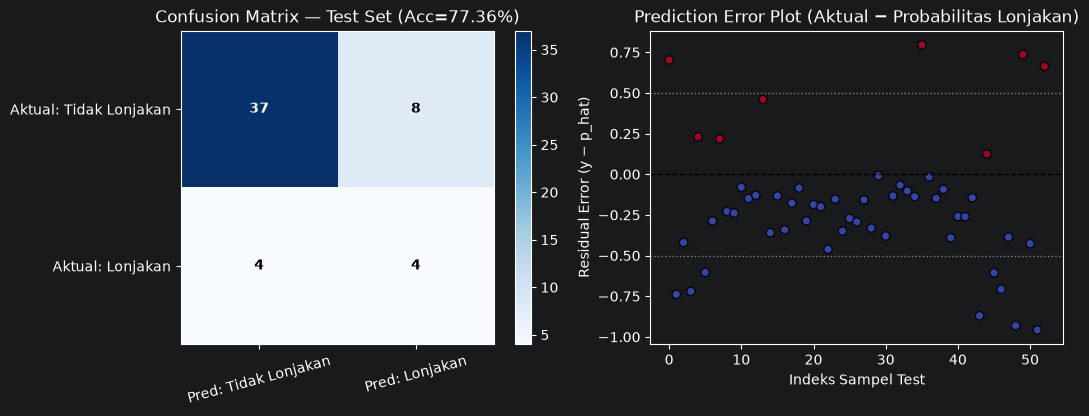

In [8]:
val_pred = best_model.transform(val_df)
val_acc = acc_evaluator.evaluate(val_pred)
val_f1 = f1_evaluator.evaluate(val_pred)
val_precision = precision_evaluator.evaluate(val_pred)
val_recall = recall_evaluator.evaluate(val_pred)

if LOWER < val_acc < UPPER:
    print(f"[Diamond 70% < X < 80% -> Yes] Validation Accuracy = {val_acc:.2%} | F1 = {val_f1:.4f}")
else:
    print(f"[Diamond 70% < X < 80% -> Batas {MAX_ROUNDS} putaran tercapai] Validation Accuracy = {val_acc:.2%} | F1 = {val_f1:.4f}")

test_pred = best_model.transform(test_df)
test_acc = acc_evaluator.evaluate(test_pred)
test_f1 = f1_evaluator.evaluate(test_pred)
test_precision = precision_evaluator.evaluate(test_pred)
test_recall = recall_evaluator.evaluate(test_pred)

print(
    f"Test Set -> Accuracy: {test_acc:.4f} | Precision (Lonjakan): {test_precision:.4f} | "
    f"Recall (Lonjakan): {test_recall:.4f} | F1: {test_f1:.4f}"
)

cm_test_pdf = test_pred.groupBy("spike_label", "prediction").count().orderBy("spike_label", "prediction").toPandas()
cm_matrix = cm_test_pdf.pivot(index="spike_label", columns="prediction", values="count").reindex(index=[0, 1], columns=[0.0, 1.0], fill_value=0)
cm_matrix.index = ["Aktual: Tidak Lonjakan", "Aktual: Lonjakan"]
cm_matrix.columns = ["Pred: Tidak Lonjakan", "Pred: Lonjakan"]
print("\nConfusion Matrix (Test Set):")
print(cm_matrix)

# Visualisasi: Confusion Matrix & Prediction Error Plot (sesuai Diagram Arsitektur)
from pyspark.ml.functions import vector_to_array

pdf_err = (
    test_pred.withColumn("prob_arr", vector_to_array("probability"))
    .select("week_date", "state", "spike_label", "prediction", F.col("prob_arr")[1].alias("prob_spike"))
    .toPandas()
)
pdf_err["prediction_error"] = pdf_err["spike_label"] - pdf_err["prob_spike"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

im = axes[0].imshow(cm_matrix.values, cmap="Blues")
fig.colorbar(im, ax=axes[0])
axes[0].set_xticks(range(2))
axes[0].set_xticklabels(cm_matrix.columns, rotation=15)
axes[0].set_yticks(range(2))
axes[0].set_yticklabels(cm_matrix.index)
for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i, int(cm_matrix.values[i, j]), ha="center", va="center",
            color="white" if cm_matrix.values[i, j] > cm_matrix.values.max() / 2 else "black",
            fontweight="bold",
        )
axes[0].set_title(f"Confusion Matrix — Test Set (Acc={test_acc:.2%})")

axes[1].scatter(range(len(pdf_err)), pdf_err["prediction_error"], c=pdf_err["spike_label"], cmap="coolwarm", alpha=0.85, edgecolors="k")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].axhline(0.5, color="gray", linestyle=":", linewidth=1)
axes[1].axhline(-0.5, color="gray", linestyle=":", linewidth=1)
axes[1].set_title("Prediction Error Plot (Aktual − Probabilitas Lonjakan)")
axes[1].set_xlabel("Indeks Sampel Test")
axes[1].set_ylabel("Residual Error (y − p_hat)")

plt.tight_layout()
plt.show()

## 8. `Contribute Rank / Importance Feature`

#1 week_of_year          : 0.3230
#2 state_idx             : 0.2918
#3 bed_occ_ratio_lag1    : 0.1225
#4 lag_1                 : 0.1129
#5 rolling_mean_4w       : 0.0789
#6 lag_2                 : 0.0709


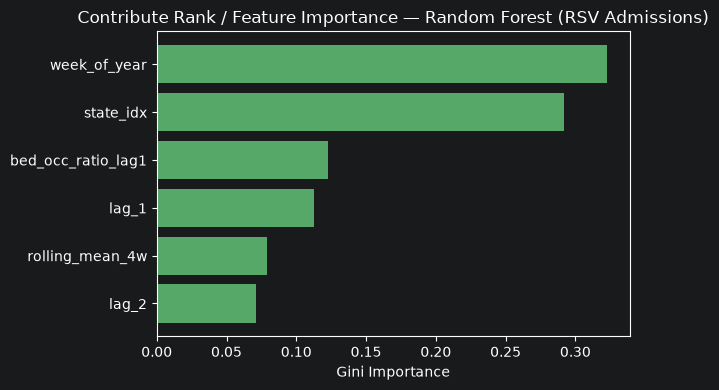

In [9]:
importances = list(zip(feature_cols, best_model.featureImportances.toArray()))
importances.sort(key=lambda x: -x[1])
for rank, (f, imp) in enumerate(importances, start=1):
    print(f"#{rank} {f:22s}: {imp:.4f}")

plt.figure(figsize=(6.5, 4))
plt.barh([f for f, _ in importances][::-1], [imp for _, imp in importances][::-1], color="#55A868")
plt.xlabel("Gini Importance")
plt.title("Contribute Rank / Feature Importance — Random Forest (RSV Admissions)")
plt.tight_layout()
plt.show()

## 9. `Load With Accuracy, Hyperparam, Treshold result` → `Stored`
Menyimpan model Spark ML (`RandomForestClassificationModel` & `StringIndexerModel`), metadata lengkap (akurasi, precision, recall, F1, hyperparameter, threshold, peringkat fitur), serta hasil prediksi panel lengkap ke Local Storage untuk dipakai oleh `bda_2` dan Warehouse/Data Mart.

In [10]:
MODEL_PATH = os.path.join(MODELS_DIR, "surge_classifier_rf")
INDEXER_PATH = os.path.join(MODELS_DIR, "state_indexer")

# Bersihkan sisa folder kosong jika run sebelumnya gagal di tengah jalan
for p in (MODEL_PATH, INDEXER_PATH):
    if os.path.isdir(p):
        shutil.rmtree(p)

spark_model_saved = False
try:
    best_model.write().overwrite().save(MODEL_PATH)
    si_model.write().overwrite().save(INDEXER_PATH)
    spark_model_saved = True
    print("Model Spark ML native tersimpan di:", MODEL_PATH)
except Exception as exc:
    print(f"[Info] Penyimpanan native Spark ML dilewati ({exc}); menyimpan prediksi & metadata lengkap via Parquet/JSON.")

# Simpan prediksi lengkap seluruh panel untuk dipakai BDA & Warehouse
full_pred_df = (
    best_model.transform(df_feat)
    .withColumn("prob_arr", vector_to_array("probability"))
    .withColumn("spike_probability", F.round(F.col("prob_arr")[1], 4))
    .withColumn("predicted_spike", F.col("prediction").cast("int"))
    .drop("features", "rawPrediction", "probability", "prob_arr", "prediction")
)
pred_panel_path = os.path.join(PROCESSED_DIR, "rsv_predictions_panel.parquet")
save_parquet_pure_spark(full_pred_df, pred_panel_path)

# Pastikan importances selalu tersedia meskipun sel dijalankan terpisah
importances = sorted(
    zip(feature_cols, best_model.featureImportances.toArray()),
    key=lambda x: -x[1],
)

metadata = {
    "model_type": "RandomForestClassifier (Spark ML)",
    "spark_native_saved": spark_model_saved,
    "dataset": "noeyislearning/weekly-hospital-respiratory-data-and-metrics (RSV Admissions branch)",
    "feature_cols": feature_cols,
    "state_labels": list(si_model.labels),
    "feature_importance_rank": [{"rank": i + 1, "feature": f, "importance": float(imp)} for i, (f, imp) in enumerate(importances)],
    "target": "Total RSV Admissions",
    "label": "spike_label (1 = top 30% kenaikan mingguan RSV Admissions)",
    "spike_threshold_pct_change": float(SPIKE_THRESHOLD),
    "hyperparameters": {
        "maxDepth": int(best_model.getOrDefault("maxDepth")),
        "numTrees": int(best_model.getOrDefault("numTrees")),
        "maxBins": 64,
        "seed": 42,
    },
    "tuning_rounds_used": round_num,
    "validation_metrics": {
        "accuracy": float(val_acc),
        "precision": float(val_precision),
        "recall": float(val_recall),
        "f1": float(val_f1),
    },
    "test_metrics": {
        "accuracy": float(test_acc),
        "precision": float(test_precision),
        "recall": float(test_recall),
        "f1": float(test_f1),
    },
    "target_accuracy_range": [LOWER, UPPER],
}

meta_path = os.path.join(MODELS_DIR, "surge_classifier_rf_metadata.json")
with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Metadata hasil model tersimpan di:", meta_path)
print("Prediksi panel tersimpan di:", pred_panel_path)

Model Spark ML native tersimpan di: ../models\surge_classifier_rf
Metadata hasil model tersimpan di: ../models\surge_classifier_rf_metadata.json
Prediksi panel tersimpan di: ../data/processed\rsv_predictions_panel.parquet
